# 🧹 Notebook 02 — Limpeza e Pré-processamento dos Dados

### Dataset: Cardiovascular Disease Prediction
### Disciplina: DCT1401 — Inteligência Artificial (UFRN)
### Aluna: Mariana dos Santos Batista Medeiros — Matrícula: 20230083988

Este notebook realiza a limpeza e o pré-processamento do conjunto de dados a partir dos problemas identificados no Notebook 01.

A sequência adotada é:

1. Carregamento dos dados brutos
2. Tratamento de valores ausentes
3. Avaliação e decisão sobre os outliers
4. Estatísticas descritivas, distribuições e correlação após o tratamento
5. Codificação das variáveis categóricas
6. Avaliação e aplicação da normalização/padronização
7. Remoção do identificador
8. Salvamento dos datasets processados

As análises estatísticas e de correlação são realizadas somente após o tratamento dos valores ausentes e a decisão sobre os outliers.

## 🔧 Configuração Inicial

In [1]:
# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento
from sklearn.preprocessing import StandardScaler

# Organização dos caminhos do projeto
from pathlib import Path


# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 50)


# ---------------------------------------------------------
# Localização automática da raiz do projeto
# ---------------------------------------------------------

diretorio_atual = Path.cwd()

if diretorio_atual.name == "notebooks":
    raiz_projeto = diretorio_atual.parent

elif (diretorio_atual / "data" / "raw").exists():
    raiz_projeto = diretorio_atual

else:
    raise FileNotFoundError(
        "Não foi possível localizar a estrutura do projeto."
    )


# ---------------------------------------------------------
# Caminhos utilizados no projeto
# ---------------------------------------------------------

caminho_dataset = (
    raiz_projeto
    / "data"
    / "raw"
    / "cardiovascular_disease_prediction.csv"
)

pasta_figuras = raiz_projeto / "reports" / "figures"
pasta_processados = raiz_projeto / "data" / "processed"

pasta_figuras.mkdir(parents=True, exist_ok=True)
pasta_processados.mkdir(parents=True, exist_ok=True)


print("Bibliotecas carregadas com sucesso!")
print(f"Raiz do projeto: {raiz_projeto}")

Bibliotecas carregadas com sucesso!
Raiz do projeto: c:\Users\farma\OneDrive\Documentos\IA\projeto_cardiovascular


---
## 📁 1. Carregamento dos Dados Brutos

Carregamos o dataset original, sem nenhuma modificação.

In [2]:
# Carregamento do dataset original
df = pd.read_csv(
    caminho_dataset,
    sep=",",
    encoding="utf-8"
)

print(f"Dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Valores ausentes totais: {df.isnull().sum().sum()}")

df.head(3)

Dataset carregado: 20000 linhas x 35 colunas
Valores ausentes totais: 4800


,Patient_ID,Age,Gender,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Cholesterol,HDL,LDL,Triglycerides,Blood_Glucose,Diabetes,Hypertension,Smoking,Alcohol_Consumption,Physical_Activity,Exercise_Days_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Stress_Level,Family_History,Chest_Pain,Shortness_of_Breath,ECG_Result,Medication,Diet_Quality,Annual_Income_USD,Region,Education_Level,BMI_Category,Risk_Score,Cardiovascular_Disease
0,110651,41,Female,165.6,89.0,32.5,118,79,85,248,44.0,NaN,255.0,93.0,No,No,Yes,No,Moderate,7,56,8.5,High,No,No,No,Normal,No,Average,109870,Central,Bachelor,Obese,7.63,0
1,102042,43,Female,163.1,40.0,15.0,114,55,73,219,58.0,96.0,176.0,75.0,No,No,No,No,Moderate,2,42,7.0,Low,No,No,Yes,Normal,No,Poor,33025,North,Master,Underweight,2.96,0
2,108669,37,Female,154.0,96.2,40.6,127,74,68,219,23.0,107.0,231.0,118.0,No,No,Yes,Yes,Low,5,82,7.7,Moderate,No,No,No,Normal,No,Poor,53705,South,Bachelor,Obese,9.73,0


### 1.1 Verificação de duplicatas

Antes da limpeza, verificamos se existem registros totalmente duplicados ou identificadores repetidos.

In [3]:
print("Linhas totalmente duplicadas:", df.duplicated().sum())
print("Patient_ID duplicados:", df["Patient_ID"].duplicated().sum())

Linhas totalmente duplicadas: 0
Patient_ID duplicados: 0


---
## 🔧 2. Tratamento de Valores Ausentes

Na EDA foram identificadas oito variáveis com valores ausentes, cada uma com 600 registros faltantes (3%).

A estratégia adotada considera o tipo e as características de cada variável:

| Coluna | Tipo | Estratégia | Justificativa |
|---|---|---|---|
| `BMI` | Numérica | **Recálculo** | Pode ser obtido diretamente a partir de `Weight_kg` e `Height_cm`, que não possuem valores ausentes |
| `HDL` | Numérica | **Mediana** | Estratégia robusta à presença de valores extremos |
| `LDL` | Numérica | **Mediana** | Estratégia robusta à presença de valores extremos |
| `Triglycerides` | Numérica | **Mediana** | Estratégia robusta à presença de valores extremos |
| `Blood_Glucose` | Numérica | **Mediana** | Estratégia robusta à presença de valores extremos |
| `Sleep_Hours` | Numérica | **Mediana** | Estratégia simples e robusta para os poucos valores ausentes |
| `Physical_Activity` | Categórica ordinal | **Moda** | Mantém uma categoria válida e utiliza a categoria mais frequente |
| `Diet_Quality` | Categórica ordinal | **Moda** | Mantém uma categoria válida e utiliza a categoria mais frequente |

Como o percentual de ausência é de apenas 3% por variável, optou-se pela imputação em vez da remoção de registros, evitando perda desnecessária de observações.

In [4]:
# Criando cópia para trabalhar
df_limpo = df.copy()

# Visualizando os ausentes antes do tratamento
print("ANTES do tratamento:")
print("=" * 50)
ausentes_antes = df_limpo.isnull().sum()
ausentes_antes = ausentes_antes[ausentes_antes > 0]
print(ausentes_antes)
print(f"\nTotal de valores ausentes: {df_limpo.isnull().sum().sum()}")

ANTES do tratamento:
BMI                  600
HDL                  600
LDL                  600
Triglycerides        600
Blood_Glucose        600
Physical_Activity    600
Sleep_Hours          600
Diet_Quality         600
dtype: int64

Total de valores ausentes: 4800


### 2.1 Reconstrução dos valores ausentes de BMI

Como `BMI` é calculado a partir do peso e da altura, verificamos inicialmente se a fórmula reproduz os valores já existentes no dataset. Em seguida, utilizamos o cálculo para preencher apenas os registros ausentes.

In [5]:
# Cálculo do BMI a partir do peso e da altura
bmi_calculado = (
    df_limpo["Weight_kg"]
    / (df_limpo["Height_cm"] / 100) ** 2
).round(1)

# Verificação com os valores de BMI já existentes
mascara_existentes = df_limpo["BMI"].notna()

coincidencia = (
    df_limpo.loc[mascara_existentes, "BMI"]
    == bmi_calculado.loc[mascara_existentes]
).all()

print("O cálculo reproduz todos os valores existentes de BMI:", coincidencia)

# Quantidade que será preenchida
qtd_bmi_ausentes = df_limpo["BMI"].isna().sum()
print("Valores ausentes de BMI antes:", qtd_bmi_ausentes)

# Preenchimento apenas dos BMI ausentes
df_limpo.loc[df_limpo["BMI"].isna(), "BMI"] = (
    bmi_calculado[df_limpo["BMI"].isna()]
)

print("Valores ausentes de BMI depois:", df_limpo["BMI"].isna().sum())

O cálculo reproduz todos os valores existentes de BMI: True
Valores ausentes de BMI antes: 600
Valores ausentes de BMI depois: 0


### 2.2 Imputação das demais variáveis numéricas pela mediana

In [6]:
# Variáveis numéricas restantes com valores ausentes
colunas_num_ausentes = [
    "HDL",
    "LDL",
    "Triglycerides",
    "Blood_Glucose",
    "Sleep_Hours"
]

print("Imputação pela MEDIANA:")
print("=" * 50)

for col in colunas_num_ausentes:
    mediana = df_limpo[col].median()
    df_limpo[col] = df_limpo[col].fillna(mediana)

    print(f"{col}: mediana = {mediana:.2f}")

print(
    "\nAusentes restantes nessas variáveis:",
    df_limpo[colunas_num_ausentes].isnull().sum().sum()
)

Imputação pela MEDIANA:
HDL: mediana = 54.00
LDL: mediana = 119.00
Triglycerides: mediana = 150.00
Blood_Glucose: mediana = 105.00
Sleep_Hours: mediana = 7.00

Ausentes restantes nessas variáveis: 0


### 2.3 Imputação das variáveis categóricas pela moda

In [7]:
colunas_cat_ausentes = [
    "Physical_Activity",
    "Diet_Quality"
]

print("Imputação pela MODA:")
print("=" * 50)

for col in colunas_cat_ausentes:
    moda = df_limpo[col].mode()[0]
    df_limpo[col] = df_limpo[col].fillna(moda)

    print(f"{col}: moda = '{moda}'")

print(
    "\nAusentes restantes nas categóricas:",
    df_limpo[colunas_cat_ausentes].isnull().sum().sum()
)

Imputação pela MODA:
Physical_Activity: moda = 'Moderate'
Diet_Quality: moda = 'Average'

Ausentes restantes nas categóricas: 0


### 2.4 Verificação pós-tratamento



In [8]:
print("DEPOIS do tratamento:")
print("=" * 50)

total_ausentes = df_limpo.isnull().sum().sum()

print(f"Total de valores ausentes: {total_ausentes}")

if total_ausentes == 0:
    print("Nenhuma coluna possui valores ausentes.")
else:
    print("ATENÇÃO: ainda existem valores ausentes.")

DEPOIS do tratamento:
Total de valores ausentes: 0
Nenhuma coluna possui valores ausentes.


---
## 📦 3. Avaliação e Tratamento de Outliers

Na EDA foram identificados possíveis outliers nas variáveis numéricas. Após o tratamento dos valores ausentes, o método IQR é aplicado novamente, pois a imputação pode alterar discretamente os quartis e, consequentemente, os limites utilizados na detecção.

Nesta etapa, o objetivo é verificar os valores extremos no conjunto tratado e decidir se serão removidos, transformados ou mantidos.

In [9]:
# Variáveis numéricas adequadas para análise de outliers
# Patient_ID é identificador.
# Cardiovascular_Disease é categórica binária.

variaveis_outliers = [
    col for col in df_limpo.select_dtypes(include=np.number).columns
    if col not in ["Patient_ID", "Cardiovascular_Disease"]
]

resultados_outliers = []

for col in variaveis_outliers:
    serie = df_limpo[col]

    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    mascara_outlier = (
        (serie < limite_inferior)
        | (serie > limite_superior)
    )

    resultados_outliers.append({
        "Variável": col,
        "Mínimo": serie.min(),
        "Máximo": serie.max(),
        "Limite Inferior": limite_inferior,
        "Limite Superior": limite_superior,
        "Qtd Outliers": mascara_outlier.sum(),
        "% Outliers": mascara_outlier.mean() * 100
    })

tabela_outliers = pd.DataFrame(resultados_outliers)

display(tabela_outliers.round(2))

print(
    "\nVariáveis com pelo menos um outlier:",
    (tabela_outliers["Qtd Outliers"] > 0).sum()
)

,Variável,Mínimo,Máximo,Limite Inferior,Limite Superior,Qtd Outliers,% Outliers
0,Age,20.00,85.0,-13.50,118.50,0,0.00
1,Height_cm,145.00,200.0,140.80,195.20,55,0.27
2,Weight_kg,40.00,128.2,31.30,112.90,60,0.30
3,BMI,10.20,56.5,9.20,42.00,186,0.93
4,Blood_Pressure_Systolic,90.00,193.0,77.00,173.00,64,0.32
5,Blood_Pressure_Diastolic,55.00,130.0,45.50,113.50,45,0.22
6,Heart_Rate,45.00,112.0,48.50,100.50,210,1.05
7,Cholesterol,120.00,350.0,94.50,314.50,44,0.22
8,HDL,20.00,100.0,16.50,92.50,107,0.53
9,LDL,50.00,244.0,29.50,209.50,92,0.46



Variáveis com pelo menos um outlier: 13


> 💡 **Decisão sobre os outliers**
>
> Após o tratamento dos valores ausentes, o método IQR continuou identificando valores extremos em parte das variáveis numéricas. Entretanto, a proporção de observações sinalizadas é baixa e o próprio conjunto de dados não fornece evidências suficientes para classificá-las como erros de registro.
>
> Como a remoção automática pelo critério do IQR poderia eliminar observações válidas e alterar a distribuição original dos dados, optou-se por **manter os outliers**.
>
> Assim, nesta etapa, o tratamento dos outliers consiste na decisão fundamentada de preservá-los, em vez de removê-los ou substituí-los.

---
## 📊 4. Análise Estatística dos Dados Tratados

Após o tratamento dos valores ausentes e a decisão sobre os outliers, o conjunto de dados está preparado para as análises estatísticas e de correlação.

As análises desta seção são realizadas sobre os dados tratados, evitando que valores ausentes interfiram nos resultados.

### 4.1 Estatísticas descritivas das variáveis numéricas

In [10]:
# Variáveis quantitativas utilizadas na análise estatística
# Patient_ID é identificador e Cardiovascular_Disease é categórica binária.

variaveis_quantitativas = [
    col for col in df_limpo.select_dtypes(include=np.number).columns
    if col not in ["Patient_ID", "Cardiovascular_Disease"]
]

estatisticas = df_limpo[variaveis_quantitativas].describe().T

# Inclusão explícita da mediana
estatisticas["Mediana"] = df_limpo[variaveis_quantitativas].median()

estatisticas = estatisticas[
    ["count", "mean", "Mediana", "std", "min", "25%", "75%", "max"]
]

estatisticas.columns = [
    "Contagem",
    "Média",
    "Mediana",
    "Desvio Padrão",
    "Mínimo",
    "Q1",
    "Q3",
    "Máximo"
]

estatisticas.round(2)

,Contagem,Média,Mediana,Desvio Padrão,Mínimo,Q1,Q3,Máximo
Age,20000.0,52.53,52.00,19.06,20.00,36.00,69.00,85.0
Height_cm,20000.0,168.02,168.00,9.90,145.00,161.20,174.80,200.0
Weight_kg,20000.0,72.17,72.20,14.80,40.00,61.90,82.30,128.2
BMI,20000.0,25.83,25.50,6.15,10.20,21.50,29.70,56.5
Blood_Pressure_Systolic,20000.0,124.78,124.00,17.63,90.00,113.00,137.00,193.0
Blood_Pressure_Diastolic,20000.0,79.60,80.00,11.77,55.00,71.00,88.00,130.0
Heart_Rate,20000.0,74.49,75.00,9.98,45.00,68.00,81.00,112.0
Cholesterol,20000.0,204.89,204.00,39.53,120.00,177.00,232.00,350.0
HDL,20000.0,54.52,54.00,14.57,20.00,45.00,64.00,100.0
LDL,20000.0,119.70,119.00,33.63,50.00,97.00,142.00,244.0


### 4.2 Frequências das variáveis categóricas

In [11]:
# Variáveis categóricas textuais
variaveis_categoricas = (
    df_limpo.select_dtypes(include="object").columns.tolist()
)

# Cardiovascular_Disease é categórica binária,
# embora esteja armazenada numericamente como 0 e 1.
variaveis_categoricas.append("Cardiovascular_Disease")

tabelas_frequencia = []

for col in variaveis_categoricas:

    frequencia = (
        df_limpo[col]
        .value_counts(dropna=False)
        .rename_axis("Categoria")
        .reset_index(name="Frequência")
    )

    frequencia.insert(0, "Variável", col)

    frequencia["Percentual (%)"] = (
        frequencia["Frequência"] / len(df_limpo) * 100
    ).round(2)

    tabelas_frequencia.append(frequencia)

frequencias_categoricas = pd.concat(
    tabelas_frequencia,
    ignore_index=True
)

frequencias_categoricas

C:\Users\farma\AppData\Local\Temp\ipykernel_19876\4228313097.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_limpo.select_dtypes(include="object").columns.tolist()


,Variável,Categoria,Frequência,Percentual (%)
0,Gender,Female,10445,52.22
1,Gender,Male,9555,47.78
2,Diabetes,No,13912,69.56
3,Diabetes,Yes,6088,30.44
4,Hypertension,No,14069,70.34
5,Hypertension,Yes,5931,29.65
6,Smoking,No,14367,71.84
7,Smoking,Yes,5633,28.17
8,Alcohol_Consumption,No,12972,64.86
9,Alcohol_Consumption,Yes,7028,35.14


### 4.3 Análise de Correlação

A correlação de Pearson é calculada entre as variáveis quantitativas após o tratamento dos dados. `Patient_ID` não é incluído por ser apenas um identificador, e `Cardiovascular_Disease` será analisada como variável categórica no problema de classificação.

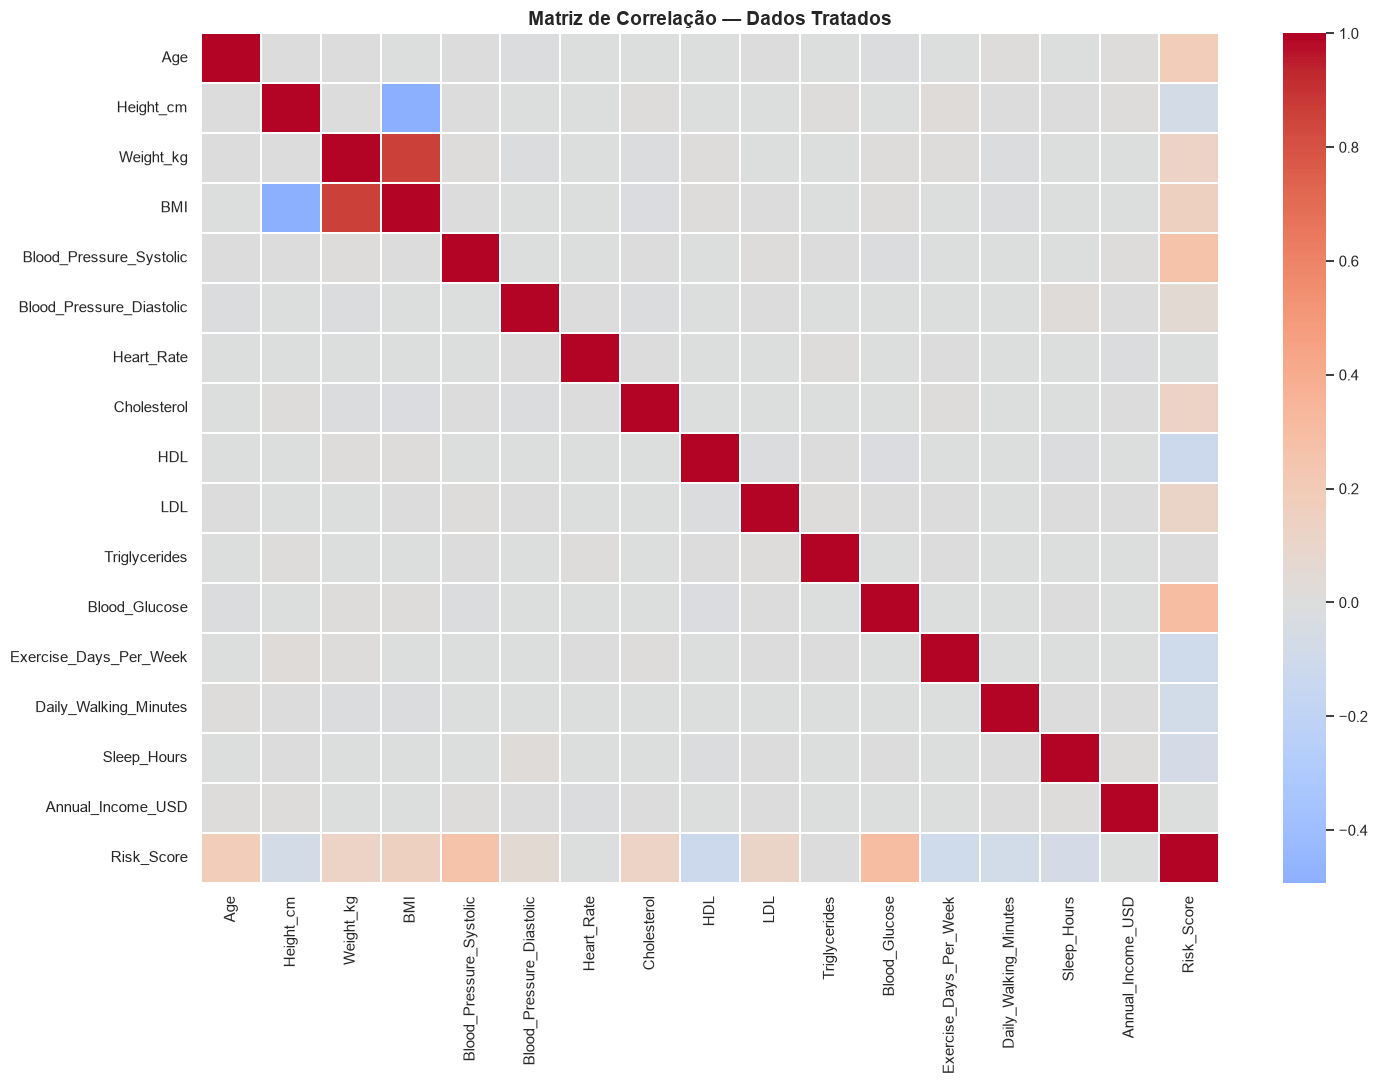

Gráfico salvo em: reports/figures/correlation_matrix.png


In [12]:
matriz_corr = df_limpo[variaveis_quantitativas].corr(method="pearson")

plt.figure(figsize=(15, 11))

sns.heatmap(
    matriz_corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title(
    "Matriz de Correlação — Dados Tratados",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    pasta_figuras / "correlation_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo em: reports/figures/correlation_matrix.png")

In [13]:
pares_correlacao = []

for i, var1 in enumerate(matriz_corr.columns):

    for var2 in matriz_corr.columns[i + 1:]:

        correlacao = matriz_corr.loc[var1, var2]

        if abs(correlacao) >= 0.50:
            pares_correlacao.append({
                "Variável 1": var1,
                "Variável 2": var2,
                "Correlação": correlacao
            })

pares_correlacao = pd.DataFrame(pares_correlacao)

if not pares_correlacao.empty:

    pares_correlacao["Correlação Absoluta"] = (
        pares_correlacao["Correlação"].abs()
    )

    pares_correlacao = pares_correlacao.sort_values(
        "Correlação Absoluta",
        ascending=False
    )

    display(
        pares_correlacao.drop(
            columns="Correlação Absoluta"
        ).round(3)
    )

else:
    print("Nenhum par apresentou |correlação| >= 0,50.")

,Variável 1,Variável 2,Correlação
0,Weight_kg,BMI,0.86


> 💡 **Interpretação:** A principal correlação elevada ocorre entre `Weight_kg` e `BMI`, com associação positiva forte. Esse resultado é esperado, pois o BMI é calculado a partir do peso e da altura. Em modelos lineares, a presença simultânea dessas variáveis deve ser avaliada devido à possível redundância e multicolinearidade. As demais correlações entre variáveis quantitativas são de menor magnitude. Não foram identificadas correlações negativas com magnitude igual ou superior a 0,50.

### 4.4 Distribuição de variáveis numéricas

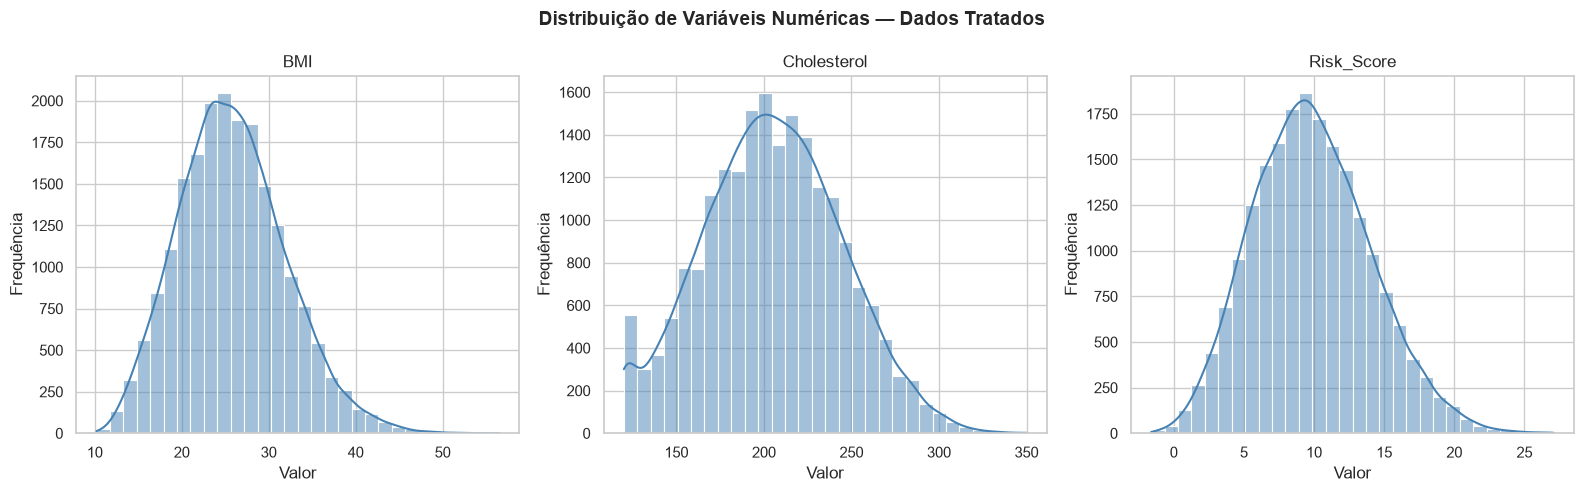

In [14]:
variaveis_distribuicao = [
    "BMI",
    "Cholesterol",
    "Risk_Score"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

for ax, col in zip(axes, variaveis_distribuicao):

    sns.histplot(
        df_limpo[col],
        bins=30,
        kde=True,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(col)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frequência")

plt.suptitle(
    "Distribuição de Variáveis Numéricas — Dados Tratados",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    pasta_figuras / "numeric_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

> 💡 Os histogramas permitem observar a forma das distribuições após o tratamento dos valores ausentes, sem remover os valores extremos identificados pelo IQR.

### 4.5 Distribuição de variáveis categóricas

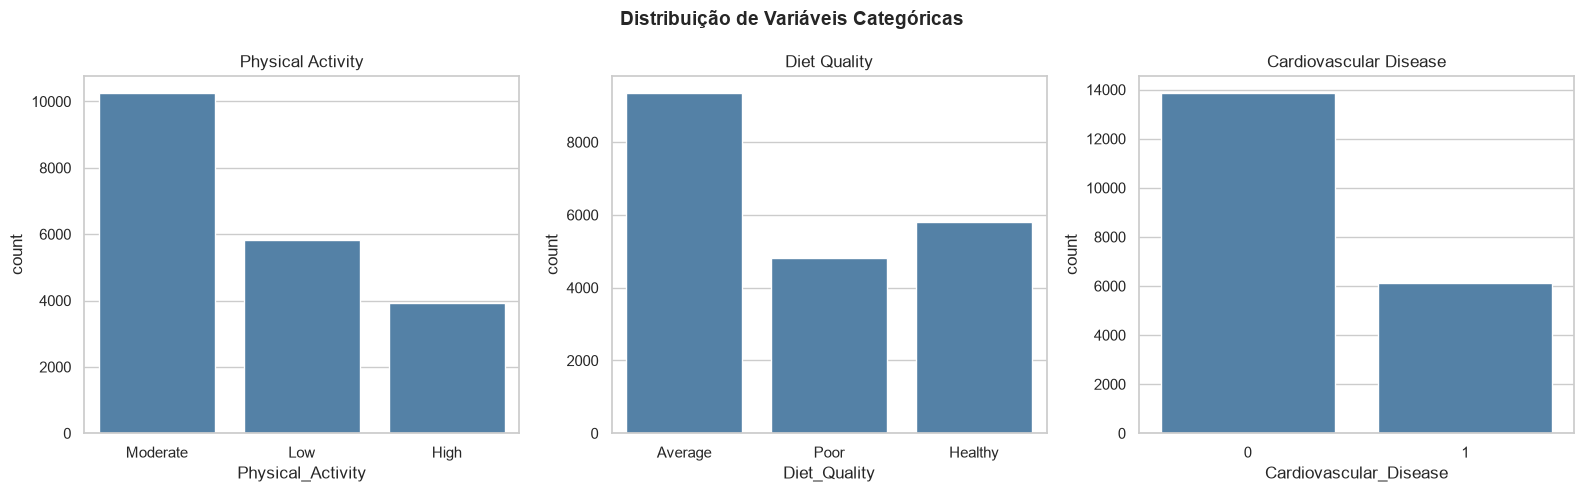

In [15]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

sns.countplot(
    data=df_limpo,
    x="Physical_Activity",
    ax=axes[0],
    color="steelblue"
)

sns.countplot(
    data=df_limpo,
    x="Diet_Quality",
    ax=axes[1],
    color="steelblue"
)

sns.countplot(
    data=df_limpo,
    x="Cardiovascular_Disease",
    ax=axes[2],
    color="steelblue"
)

axes[0].set_title("Physical Activity")
axes[1].set_title("Diet Quality")
axes[2].set_title("Cardiovascular Disease")

plt.suptitle(
    "Distribuição de Variáveis Categóricas",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    pasta_figuras / "categorical_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

---
## 🏷️ 5. Codificação das Variáveis Categóricas

Algoritmos de Machine Learning trabalham com **números**, não com texto. Por isso, precisamos converter as variáveis categóricas em valores numéricos.

Existem **3 técnicas principais**, cada uma adequada para um tipo de variável:

| Técnica | Quando usar | Exemplo |
|---------|------------|---------|
| **Label Encoding / mapeamento binário** | Variáveis **binárias** (2 categorias) | Gender: Female→0, Male→1 |
| **Ordinal Encoding** | Variáveis com **ordem natural** entre categorias | Diet_Quality: Poor → Average → Healthy |
| **One-Hot Encoding** | Variáveis **nominais** (sem ordem) com poucas categorias | Region: cria uma coluna para cada região |

> 💡 **Por que não usar Label Encoding em tudo?** Porque o Label Encoding atribui números sequenciais (0, 1, 2, 3...), e o modelo pode interpretar que "3 é maior que 1", criando uma relação de ordem falsa. Para variáveis nominais como Region, "North" não é "maior" que "South".

### 5.1 Codificação das variáveis binárias

`Cardiovascular_Disease` já está codificada como 0 e 1 no dataset original e, por isso, não necessita de uma nova transformação. Para as demais variáveis binárias, foi utilizado mapeamento explícito para 0 e 1.

In [16]:
mapas_binarios = {

    "Gender": {
        "Female": 0,
        "Male": 1
    },

    "Diabetes": {
        "No": 0,
        "Yes": 1
    },

    "Hypertension": {
        "No": 0,
        "Yes": 1
    },

    "Smoking": {
        "No": 0,
        "Yes": 1
    },

    "Alcohol_Consumption": {
        "No": 0,
        "Yes": 1
    },

    "Family_History": {
        "No": 0,
        "Yes": 1
    },

    "Chest_Pain": {
        "No": 0,
        "Yes": 1
    },

    "Shortness_of_Breath": {
        "No": 0,
        "Yes": 1
    },

    "ECG_Result": {
        "Normal": 0,
        "Abnormal": 1
    },

    "Medication": {
        "No": 0,
        "Yes": 1
    }
}

for coluna, mapa in mapas_binarios.items():
    df_limpo[coluna] = df_limpo[coluna].map(mapa)

print("Variáveis binárias codificadas com sucesso.")

Variáveis binárias codificadas com sucesso.


### 5.2 Codificação das variáveis ordinais

In [17]:
mapas_ordinais = {

    "Physical_Activity": {
        "Low": 0,
        "Moderate": 1,
        "High": 2
    },

    "Stress_Level": {
        "Low": 0,
        "Moderate": 1,
        "High": 2
    },

    "Diet_Quality": {
        "Poor": 0,
        "Average": 1,
        "Healthy": 2
    },

    "Education_Level": {
        "High School": 0,
        "Bachelor": 1,
        "Master": 2,
        "PhD": 3
    },

    "BMI_Category": {
        "Underweight": 0,
        "Normal": 1,
        "Overweight": 2,
        "Obese": 3
    }
}

for coluna, mapa in mapas_ordinais.items():
    df_limpo[coluna] = df_limpo[coluna].map(mapa)

print("Variáveis ordinais codificadas com sucesso.")

Variáveis ordinais codificadas com sucesso.


### 5.3 One-Hot Encoding da variável nominal

In [18]:
print(
    "Categorias de Region:",
    df_limpo["Region"].unique().tolist()
)

df_limpo = pd.get_dummies(
    df_limpo,
    columns=["Region"],
    drop_first=True,
    dtype=int
)

colunas_region = [
    col for col in df_limpo.columns
    if col.startswith("Region_")
]

print("Novas colunas criadas:")
for col in colunas_region:
    print("-", col)

Categorias de Region: ['Central', 'North', 'South', 'West', 'East']
Novas colunas criadas:
- Region_East
- Region_North
- Region_South
- Region_West


### 5.4 Verificação pós-codificação

In [19]:
colunas_texto_restantes = (
    df_limpo
    .select_dtypes(include="object")
    .columns
    .tolist()
)

total_ausentes = df_limpo.isnull().sum().sum()

print("Colunas textuais restantes:", colunas_texto_restantes)
print("Valores ausentes após a codificação:", total_ausentes)

if not colunas_texto_restantes and total_ausentes == 0:
    print("Codificação concluída sem inconsistências.")
else:
    print("ATENÇÃO: revisar a codificação.")

Colunas textuais restantes: []
Valores ausentes após a codificação: 0
Codificação concluída sem inconsistências.


---
## ⚖️ 6. Padronização das Variáveis Numéricas

As variáveis quantitativas do dataset apresentam escalas bastante diferentes. Por exemplo, `Annual_Income_USD` possui valores na casa de milhares, enquanto variáveis como `BMI` e `Sleep_Hours` apresentam valores em escalas muito menores.

Essa diferença pode influenciar algoritmos sensíveis à escala das variáveis, como SVM e modelos lineares regularizados.

Entre as técnicas de escalonamento disponíveis estão o **Min-Max Scaling**, que transforma os valores para uma faixa comum, geralmente entre 0 e 1, e o **StandardScaler (Z-score)**, que transforma os dados para que cada variável apresente média aproximadamente 0 e desvio padrão aproximadamente 1.

Para este projeto, optou-se pelo **StandardScaler**, considerando sua adequação aos algoritmos sensíveis à escala sugeridos para as etapas posteriores.

A padronização será aplicada às variáveis quantitativas utilizadas como features. As variáveis categóricas já codificadas e os targets `Risk_Score` e `Cardiovascular_Disease` serão preservados em suas representações originais.

In [20]:
colunas_escalar = [
    "Age",
    "Height_cm",
    "Weight_kg",
    "BMI",
    "Blood_Pressure_Systolic",
    "Blood_Pressure_Diastolic",
    "Heart_Rate",
    "Cholesterol",
    "HDL",
    "LDL",
    "Triglycerides",
    "Blood_Glucose",
    "Exercise_Days_Per_Week",
    "Daily_Walking_Minutes",
    "Sleep_Hours",
    "Annual_Income_USD"
]

print("Quantidade de variáveis que serão padronizadas:", len(colunas_escalar))

Quantidade de variáveis que serão padronizadas: 16


In [21]:
# Aplicação do StandardScaler às variáveis quantitativas

scaler = StandardScaler()

df_limpo[colunas_escalar] = scaler.fit_transform(
    df_limpo[colunas_escalar]
)

print("StandardScaler aplicado com sucesso.")
print("Quantidade de variáveis padronizadas:", len(colunas_escalar))

StandardScaler aplicado com sucesso.
Quantidade de variáveis padronizadas: 16


In [22]:
# Verificação da padronização

verificacao_padronizacao = (
    df_limpo[colunas_escalar]
    .describe()
    .loc[["mean", "std"]]
    .round(3)
)

display(verificacao_padronizacao)

,Age,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Cholesterol,HDL,LDL,Triglycerides,Blood_Glucose,Exercise_Days_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Annual_Income_USD
mean,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


---
## 🗑️ 7. Remoção do Patient_ID

A coluna `Patient_ID` é utilizada apenas como identificador e não representa uma característica preditiva do paciente. Por esse motivo, ela será removida dos datasets destinados à modelagem.

In [23]:
df_limpo = df_limpo.drop(
    columns=["Patient_ID"]
)

print("Patient_ID removido.")
print(
    f"Dataset atual: "
    f"{df_limpo.shape[0]} linhas x "
    f"{df_limpo.shape[1]} colunas"
)

Patient_ID removido.
Dataset atual: 20000 linhas x 37 colunas


---
## 💾 8. Salvamento dos Datasets Processados

Serão salvas três versões dos dados:

1. **dataset_clean.csv** — conjunto tratado, codificado, padronizado e sem o identificador `Patient_ID`;
2. **dataset_regression.csv** — versão destinada ao problema de regressão, com as features quantitativas padronizadas e `Risk_Score` como target;
3. **dataset_classification.csv** — versão destinada ao problema de classificação, com as features quantitativas padronizadas e `Cardiovascular_Disease` como target.

Para manter os dois problemas independentes, a variável-alvo alternativa não será utilizada como feature: `Cardiovascular_Disease` será retirada da versão de regressão e `Risk_Score` será retirada da versão de classificação.

Essa é uma decisão conservadora de preparação dos dados e não pressupõe que uma dessas variáveis tenha sido calculada a partir da outra. A seleção final das features será analisada nos Notebooks 03 e 04.

In [24]:
# ---------------------------------------------------------
# 1. Dataset limpo completo
# ---------------------------------------------------------

caminho_clean = (
    pasta_processados
    / "dataset_clean.csv"
)

df_limpo.to_csv(
    caminho_clean,
    index=False
)

print(
    f"dataset_clean.csv salvo: "
    f"{df_limpo.shape}"
)


# ---------------------------------------------------------
# 2. Dataset para regressão
# Target: Risk_Score
# ---------------------------------------------------------

df_regressao = df_limpo.drop(
    columns=["Cardiovascular_Disease"]
)

caminho_regressao = (
    pasta_processados
    / "dataset_regression.csv"
)

df_regressao.to_csv(
    caminho_regressao,
    index=False
)

print(
    f"dataset_regression.csv salvo: "
    f"{df_regressao.shape}"
)


# ---------------------------------------------------------
# 3. Dataset para classificação
# Target: Cardiovascular_Disease
# ---------------------------------------------------------

df_classificacao = df_limpo.drop(
    columns=["Risk_Score"]
)

caminho_classificacao = (
    pasta_processados
    / "dataset_classification.csv"
)

df_classificacao.to_csv(
    caminho_classificacao,
    index=False
)

print(
    f"dataset_classification.csv salvo: "
    f"{df_classificacao.shape}"
)


print(
    "\nDatasets salvos em: data/processed/"
)

dataset_clean.csv salvo: (20000, 37)
dataset_regression.csv salvo: (20000, 36)
dataset_classification.csv salvo: (20000, 36)

Datasets salvos em: data/processed/


---
## ✅ 9. Resumo Final do Pré-processamento

| Etapa | Resultado |
|---|---|
| **Valores ausentes** | `BMI` reconstruído a partir de peso e altura; 5 variáveis numéricas imputadas pela mediana e 2 categóricas pela moda |
| **Outliers** | Reavaliados pelo IQR após a imputação e mantidos mediante decisão justificada |
| **Estatísticas descritivas** | Calculadas somente após o tratamento dos dados |
| **Correlação** | Matriz de Pearson e heatmap calculados após o tratamento |
| **Visualizações** | Histogramas/KDE, gráficos de barras e heatmap |
| **Variáveis binárias** | Convertidas para 0/1 por mapeamento explícito |
| **Variáveis ordinais** | Convertidas preservando a ordem das categorias |
| **Variável nominal** | `Region` codificada por One-Hot Encoding |
| **Padronização** | StandardScaler aplicado às 16 variáveis quantitativas antes do salvamento dos datasets processados |
| **Identificador** | `Patient_ID` removido dos dados destinados à modelagem |
| **Salvamento** | Gerados `dataset_clean.csv`, `dataset_regression.csv` e `dataset_classification.csv` com as features quantitativas padronizadas |

O conjunto de dados está preparado para as análises específicas dos problemas de regressão e classificação, que serão desenvolvidas nos Notebooks 03 e 04.